# Covariance Steering for Stochastic Path Planning

Reproduction of K. Okamoto and P. Tsiotras, *Optimal Stochastic Vehicle Path Planning Using Covariance Steering*, IEEE RA-L 4(3), 2019.

The notebook builds the method block by block, from open loop to closed loop to chance constraints and obstacles. Each block is the same code `python covsteer.py` runs; the cell under it runs that block.

| Block | What it does | Paper |
|---|---|---|
| 1 | Problem data: start, goal, horizon | Sec. IV-B |
| 2 | Vehicle model: double integrator with noise | Eq. 1 |
| 3 | Lifted dynamics: whole trajectory as one linear equation | Eq. 7 |
| 4 | Policy $u_k = v_k + K_k y_k$: mean set by $V$, covariance set by $K$ | Thm. 1, Eqs. 12–16 |
| 5 | Open loop ($K=0$): covariance can only grow | Sec. I |
| 6 | Optimal covariance steering: cost + terminal mean and covariance | Eqs. 17–19 |
| 7 | Chance constraints: keep the mean 3.09 σ from each face | Eq. 20 |
| 8 | Obstacles: overlapping boxes + binary region selection | Eqs. 22–25 |
| 9 | Algorithm 1: mixed-integer solve, certified optimal | Alg. 1, Figs. 2–4 |
| 10 | Monte Carlo verification of every promise | — |

Kernel **Python (covsteer)**. Run all: about 4 min with MOSEK.

In [1]:
import json
import sys
import time
import warnings
from functools import lru_cache
from pathlib import Path

import cvxpy as cp
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown
from scipy.stats import norm

sys.path.insert(0, "..")
from covsteer import fig_panels, fig_regions, fig_sweep     # plotting helpers only (block 11)

RESULTS = Path("../results")
warnings.filterwarnings("ignore", message="Argument sub")

## Block 1. Problem data

Start and goal distributions, horizon and bounds.

In [2]:
# ---- Block 1 (same code as covsteer.py) ----
dt, N = 0.2, 20          # 20 steps of 0.2 s = 4 s
nx, nu = 4, 2            # state [p_x, p_y, v_x, v_y], control [a_x, a_y]

mu_0 = np.array([-10.0, 0.1, 0.0, 0.0])           # start  x_0 ~ N(mu_0, Sigma_0)   ASSUMED
Sigma_0 = np.diag([0.05, 0.05, 0.001, 0.001])     # ASSUMED
mu_N = np.zeros(nx)                                # goal   x_N ~ N(mu_N, Sigma_N)   ASSUMED
Sigma_N = np.diag([0.01, 0.01, 0.001, 0.001])     # ASSUMED
V_MAX, K_MAX = 100.0, 10.0                         # bounds on V and K, from the paper

## Block 2. Vehicle model (Eq. 1)

Acceleration is the control; noise is added every step: $x_{k+1} = Ax_k + Bu_k + Dw_k$.

In [3]:
# ---- Block 2 (same code as covsteer.py) ----
I2, Z2 = np.eye(2), np.zeros((2, 2))
A = np.block([[I2, dt * I2],
              [Z2, I2]])               # position += dt * velocity
B = np.vstack([0.5 * dt**2 * I2,
               dt * I2])               # the control is the acceleration
D = 1e-2 * np.eye(nx)                  # noise scale, from the paper

## Block 3. Lifted dynamics (Eq. 7)

Unroll Eq. 1 into $X = \mathcal A x_0 + \mathcal B U + \mathcal D W$: the whole trajectory is linear in all controls.

In [4]:
# ---- Block 3 (same code as covsteer.py) ----
# The whole trajectory X = [x_0; ...; x_N] is ONE linear function of the start,
# all controls U and all noise W, so we can optimize all controls at once.


def blk(k):
    """Rows of x_k inside the stacked trajectory X."""
    return slice(k * nx, (k + 1) * nx)


def lift():
    """Build A_cal, B_cal, D_cal by unrolling Eq. 1."""
    A_pow = [np.linalg.matrix_power(A, k) for k in range(N + 1)]
    A_cal = np.vstack(A_pow)
    B_cal = np.zeros(((N + 1) * nx, N * nu))
    D_cal = np.zeros(((N + 1) * nx, N * nx))
    for k in range(1, N + 1):          # x_k depends on u_j and w_j for j < k only
        for j in range(k):
            B_cal[blk(k), j * nu:(j + 1) * nu] = A_pow[k - 1 - j] @ B
            D_cal[blk(k), blk(j)] = A_pow[k - 1 - j] @ D
    return A_cal, B_cal, D_cal


A_cal, B_cal, D_cal = lift()

In [5]:
# check: stepping Eq. 1 twenty times gives the same trajectory as Eq. 7
rng = np.random.default_rng(0)
x0, U, W = rng.normal(size=nx), rng.normal(size=N * nu), rng.normal(size=N * nx)
x, X_loop = x0, [x0]
for k in range(N):
    x = A @ x + B @ U[k * nu:(k + 1) * nu] + D @ W[k * nx:(k + 1) * nx]
    X_loop.append(x)
print("same trajectory:", np.allclose(np.concatenate(X_loop), A_cal @ x0 + B_cal @ U + D_cal @ W))

same trajectory: True


## Block 4. Policy: mean and covariance (Theorem 1)

Feed back $y_k$, the deviation caused by noise alone. Then the mean $\bar X = \mathcal A\mu_0 + \mathcal BV$ depends only on $V$, and the covariance $\Sigma_X = SS^\top$, $S=(I+\mathcal BK)L$ depends only on $K$. Both are linear: the problem stays convex.

In [6]:
# ---- Block 4 (same code as covsteer.py) ----
# Policy:  u_k = v_k + K_k y_k,   y_{k+1} = A y_k + D w_k,   y_0 = x_0 - mu_0
# y_k is the deviation the noise alone would cause. It does not depend on K, so
#     mean        X_bar   = A_cal mu_0 + B_cal V            (Eq. 15)  set by V only
#     covariance  Sigma_X = S S^T,  S = (I + B_cal K) L     (Eq. 16)  set by K only
# Both are LINEAR in the unknowns (V, K), so the problem stays convex.

# Square root of the noise-only covariance:  L L^T = A_cal Sigma_0 A_cal^T + D_cal D_cal^T
L = np.hstack([A_cal @ np.linalg.cholesky(Sigma_0), D_cal])


def policy(feedback=True):
    """Unknowns V, K and the mean and covariance they produce, as cvxpy expressions.
    feedback=False fixes K = 0 (open loop, "mean steering")."""
    V = cp.Variable(N * nu)
    if feedback:
        K = [cp.Variable((nu, nx)) for _ in range(N)]
        KL = cp.vstack([K[k] @ L[blk(k)] for k in range(N)])    # K times L, block by block
    else:
        K = None
        KL = np.zeros((N * nu, L.shape[1]))
    X_bar = A_cal @ mu_0 + B_cal @ V                             # Eq. 15
    S = L + B_cal @ KL                                           # Eq. 16
    return dict(V=V, K=K, KL=KL, X_bar=X_bar, S=S)


def solution(V, K=None, route=None):
    """The same formulas with numbers: mean and covariance at every step, and the cost."""
    if K is None:
        K = np.zeros((N, nu, nx))
    K = np.asarray(K)
    KL = np.vstack([K[k] @ L[blk(k)] for k in range(N)])
    S = L + B_cal @ KL
    sol = dict(V=V, K=K, route=route,
               mus=(A_cal @ mu_0 + B_cal @ V).reshape(N + 1, nx),
               Sigmas=np.array([S[blk(k)] @ S[blk(k)].T for k in range(N + 1)]),
               J_mean=float(V @ V),
               J_cov=float(np.sum(KL**2)))
    sol["J"] = sol["J_mean"] + sol["J_cov"]
    if route is not None:
        sol["slit"] = "upper" if route[2].any() else "lower"    # region R3 = upper slit
    return sol

## Block 5. Open loop (K = 0)

With $K=0$ the covariance is $LL^\top$ whatever $V$ is. Controls move the mean; nothing shrinks the spread.

In [7]:
# ---- Block 5 (same code as covsteer.py) ----
# With K = 0, S = L: the covariance is L L^T no matter what V is.
# The controls move the mean, but nothing can shrink the uncertainty.


def open_loop():
    """Least-energy controls V that bring the MEAN to the goal, with no feedback."""
    V = np.linalg.pinv(B_cal[blk(N)]) @ (mu_N - (A_cal @ mu_0)[blk(N)])
    return solution(V)

final variance: 0.078   target: 0.01


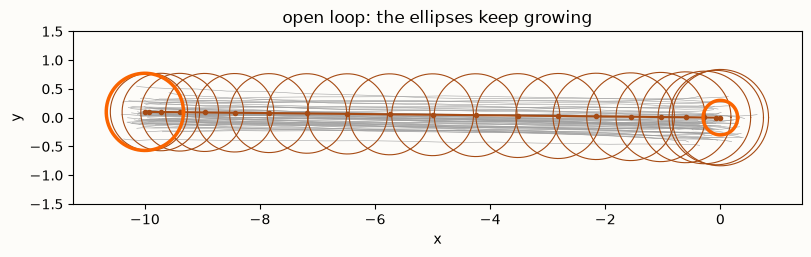

In [8]:
ol = open_loop()
print("final variance:", round(ol["Sigmas"][-1][0, 0], 3), "  target:", Sigma_N[0, 0])
fig_panels([("open loop: the ellipses keep growing", ol)], width=8);

## Block 6. Optimal covariance steering: closed loop (Eqs. 17-19)

Combine block 4 with the cost $J = \|V\|^2 + \|KL\|_F^2$ (Eq. 17), the terminal mean $E_N\bar X = \mu_N$ (Eq. 18a) and the terminal covariance $\|\Sigma_N^{-1/2}S_N\|_2 \le 1$ (Eq. 19), then solve.

In [9]:
# ---- Block 6 (same code as covsteer.py) ----
# Cost (Eq. 17): expected control energy E[sum u_k^T u_k] = ||V||^2 + ||K L||_F^2
#     (Q = 0, R = I; ASSUMED, the paper does not give them)
# Terminal mean (Eq. 18a):        E_N X_bar = mu_N
# Terminal covariance (Eq. 19):   Sigma_xN <= Sigma_N  <=>  ||Sigma_N^{-1/2} S_N||_2 <= 1
Sigma_N_inv_half = np.diag(1 / np.sqrt(np.diag(Sigma_N)))


def build(feedback=True, eq19=True):
    """Policy (block 4) + cost + terminal constraints. eq19=False leaves Eq. 19 out."""
    P = policy(feedback)
    P["J"] = cp.sum_squares(P["V"]) + cp.sum_squares(P["KL"])            # Eq. 17
    P["cons"] = [P["X_bar"][blk(N)] == mu_N,                              # Eq. 18a
                 cp.abs(P["V"]) <= V_MAX]
    if feedback:
        P["cons"] += [cp.abs(K_k) <= K_MAX for K_k in P["K"]]
        if eq19:
            P["cons"].append(cp.sigma_max(Sigma_N_inv_half @ P["S"][blk(N)]) <= 1)  # Eq. 19
    return P


@lru_cache
def has_mosek():
    """True if MOSEK is installed and licensed."""
    try:
        cp.Problem(cp.Minimize(cp.square(cp.Variable() - 1))).solve(solver=cp.MOSEK)
        return True
    except Exception:
        return False


def solve_convex(feedback=True, geom=None, route=None):
    """Solve when the problem is convex: no obstacles, or obstacles with a fixed route.
    Uses the open-source Clarabel solver (MOSEK is only needed for the mixed-integer step)."""
    P = build(feedback)
    cons = P["cons"]
    if geom is not None:
        cons = cons + region_constraints(P, geom, route)
    prob = cp.Problem(cp.Minimize(P["J"]), cons)
    try:
        prob.solve(solver=cp.CLARABEL)
    except cp.error.SolverError:          # Clarabel sometimes errors instead of "infeasible"
        return None
    if prob.status not in ("optimal", "optimal_inaccurate"):
        return None
    K = [K_k.value for K_k in P["K"]] if feedback else None
    return solution(P["V"].value, K, route)

final variance: 0.01   target: 0.01
cost J: open loop 93.99   covariance steering 94.03


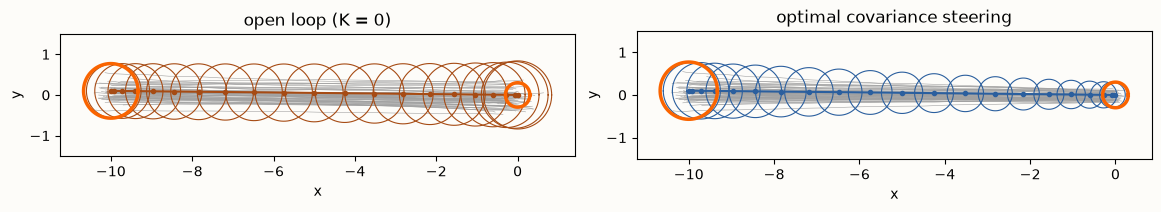

In [10]:
cl = solve_convex(feedback=True)
print("final variance:", round(cl["Sigmas"][-1][0, 0], 4), "  target:", Sigma_N[0, 0])
print("cost J: open loop", round(ol["J"], 2), "  covariance steering", round(cl["J"], 2))
fig_panels([("open loop (K = 0)", ol), ("optimal covariance steering", cl)]);

The target covariance is met exactly, for only 0.04 extra cost.

## Block 7. Chance constraints (Eq. 20)

$\Pr(a^\top x_k > b) \le \epsilon \iff a^\top\mu_k + 3.09\,\|a^\top S_k\| \le b$: keep the mean 3.09 standard deviations from each face. A cone constraint, still convex.

In [11]:
# ---- Block 7 (same code as covsteer.py) ----
# The noise is Gaussian (unbounded), so we ask each face a^T x <= b to hold
# with probability at least 1 - eps. For a Gaussian this is exact:
#     Pr(a^T x_k > b) <= eps   <=>   a^T mu_k + PHI_INV * std(a^T x_k) <= b
# i.e. keep the mean PHI_INV = 3.09 standard deviations away from the face.
# std(a^T x_k) = ||a^T S_k|| is a norm of something linear: a convex cone.
eps = 1e-3                       # allowed violation probability per face
PHI_INV = norm.ppf(1 - eps)      # = 3.09


def chance_margins(P):
    """margin[i, k] >= 3.09 * std of p_x (i = 0) or p_y (i = 1) at step k."""
    margin = cp.Variable((2, N + 1))
    cons = [margin[i] >= PHI_INV * cp.norm(P["S"][i::nx], 2, axis=1) for i in (0, 1)]
    return margin, cons

In [12]:
sigma_y = np.sqrt(ol["Sigmas"][N // 2][1, 1])          # open loop, at the wall
print(f"open loop at the wall: 3.09 * std_y = {PHI_INV * sigma_y:.2f}"
      f"   vs. half the upper slit = 0.25")

open loop at the wall: 3.09 * std_y = 0.73   vs. half the upper slit = 0.25


Without feedback the safety margin is three times too wide for the 0.5 slit.

## Block 8. Obstacles: region selection (Eqs. 22-25)

Cover the free space with boxes R1–R4. Binary $M_{r,k}=1$ puts $x_k, x_{k+1}$ in box $r$, one box per step (Eq. 24), and switches that box's chance constraints on with big-M (Eq. 25).

In [13]:
# ---- Block 8 (same code as covsteer.py) ----
# The free space is not convex (pass above OR below), so cover it with
# overlapping boxes R1..R4 (Eqs. 22-23). Binary M[r, k] = 1 means x_k and
# x_{k+1} are both in box r, so the whole segment is. One box per step (Eq. 24).
# "If M[r, k] = 1, the chance constraints of box r hold" is big-M (Eq. 25):
#     a^T mu + margin - b <= BIG_M * (1 - M[r, k])
WORKSPACE = (-12.0, 2.0, -5.0, 5.0)    # map edges (x_min, x_max, y_min, y_max)
BIG_M = 30.0                           # larger than any left-hand side on this map


def double_slit(top_gap=0.5):
    """Wall at x in [-6, -4] with two slits. RECONSTRUCTED from the paper's Figs. 2-4, 6."""
    top = 1.0 + top_gap
    return dict(top_gap=top_gap,
                obstacles=[(-6, -4, top, 5), (-6, -4, -1.4, 1.0), (-6, -4, -5, -3)],
                regions=[(-12, -6, -5, 5),       # R1: left of the wall
                         (-12, 2, -3, -1.4),     # R2: band through the lower slit (1.6 wide)
                         (-12, 2, 1.0, top),     # R3: band through the upper slit
                         (-4, 2, -5, 5)])        # R4: right of the wall


def faces(box):
    """The 4 faces of a box as (coordinate i, sign, b), meaning  sign * p_i <= b."""
    x_min, x_max, y_min, y_max = box
    return [(0, -1, -x_min), (0, 1, x_max), (1, -1, -y_min), (1, 1, y_max)]


def region_constraints(P, geom, M, forbid=()):
    """Chance constraints (block 7) inside the selected boxes.
    M is a boolean variable (solver picks the route) or a 0/1 array (route fixed)."""
    mean = [P["X_bar"][0::nx], P["X_bar"][1::nx]]      # mean p_x and p_y, k = 0..N
    margin, cons = chance_margins(P)

    for i, sign, b in faces(WORKSPACE):                # always stay on the map
        cons.append(sign * mean[i] + margin[i] <= b)

    if isinstance(M, cp.Variable):
        cons.append(cp.sum(M, axis=0) == 1)            # Eq. 24: one box per step
        cons += [M[r] == 0 for r in forbid]

    for r, box in enumerate(geom["regions"]):
        for i, sign, b in faces(box):
            for k in (slice(0, N), slice(1, N + 1)):   # both x_k and x_{k+1}
                cons.append(sign * mean[i][k] + margin[i][k] - b <= BIG_M * (1 - M[r]))  # Eq. 25
    return cons

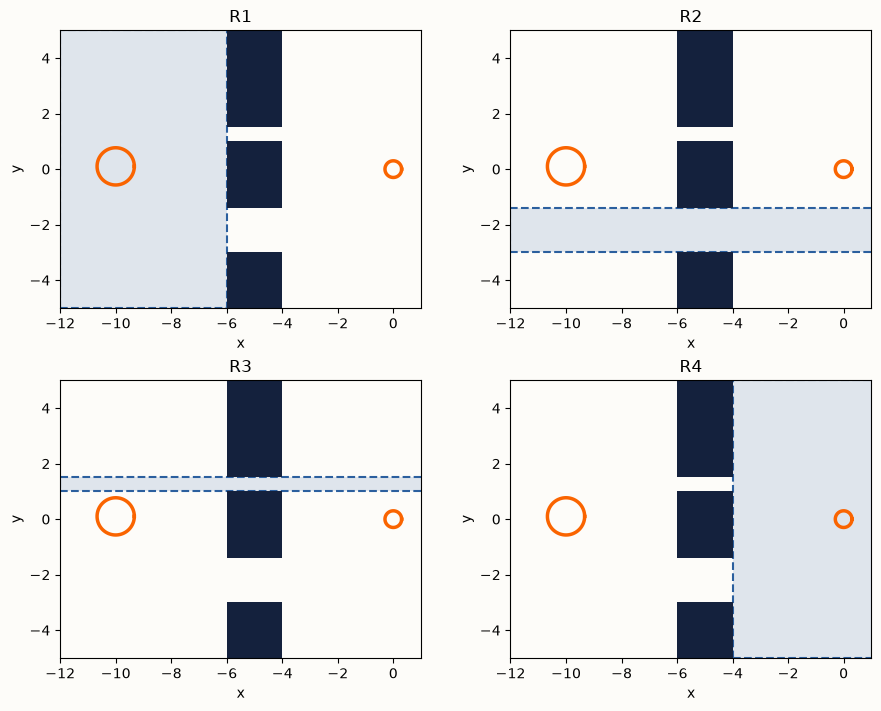

In [14]:
geom1 = double_slit(0.5)
fig_regions(geom1);

Choosing R2 or R3 is choosing the lower or the upper slit.

## Block 9. Algorithm 1: mixed-integer solve

Put blocks 6, 7 and 8 together and let MOSEK choose the route. Eq. 19 is replaced by a few cuts (lower bound); the chosen route is re-solved with the exact Eq. 19 (upper bound); equal bounds certify the optimum.

In [15]:
# ---- Block 9 (same code as covsteer.py) ----
# MOSEK solves mixed-integer SOCPs but not mixed-integer SDPs, and Eq. 19 is an
# SDP constraint. We use:   ||G||_2 <= 1   <=>   ||z^T G|| <= 1 for every unit z.
#   Lower bound: keep only a few directions z (a relaxation), solve the MISOCP.
#   Upper bound: fix the route it chose, solve with the exact Eq. 19 (convex).
#   If the bounds agree the route is certified optimal; else add the worst z, repeat.
MOSEK_OPTS = {"MSK_DPAR_MIO_MAX_TIME": 600.0, "MSK_DPAR_MIO_TOL_REL_GAP": 1e-6}

# Starting directions: the 4 axes and the 12 diagonals (e_i +- e_j) / sqrt(2)
CUT_DIRS = list(np.eye(nx))
for i in range(nx):
    for j in range(i + 1, nx):
        CUT_DIRS.append((np.eye(nx)[i] + np.eye(nx)[j]) / np.sqrt(2))
        CUT_DIRS.append((np.eye(nx)[i] - np.eye(nx)[j]) / np.sqrt(2))


def algorithm1(geom, feedback=True, forbid=(), tol=1e-4, max_iter=20):
    """Optimal route and policy through the regions of geom. Needs MOSEK. None if infeasible."""
    P = build(feedback, eq19=False)
    M = cp.Variable((len(geom["regions"]), N), boolean=True)
    cons = P["cons"] + region_constraints(P, geom, M, forbid)
    G = Sigma_N_inv_half @ P["S"][blk(N)]              # Eq. 19 is ||G||_2 <= 1
    cuts = list(CUT_DIRS) if feedback else []

    for _ in range(max_iter):
        relaxed = cp.Problem(cp.Minimize(P["J"]), cons + [cp.norm(z @ G) <= 1 for z in cuts])
        relaxed.solve(solver=cp.MOSEK, mosek_params=MOSEK_OPTS)
        if relaxed.status not in ("optimal", "optimal_inaccurate"):
            return None
        route = np.round(M.value).astype(int)
        if not feedback:                               # no Eq. 19: the MISOCP is exact
            return solution(P["V"].value, None, route)

        sol = solve_convex(True, geom, route)          # exact Eq. 19 on this route
        if sol is not None:
            sol["gap"] = (sol["J"] - relaxed.value) / sol["J"]
            if sol["gap"] <= tol:                      # bounds agree: certified optimal
                return sol
        cuts.append(np.linalg.svd(G.value)[0][:, 0])   # most violated direction
    raise RuntimeError("Algorithm 1: no optimality certificate after max_iter iterations")


def route_str(route):
    """Box chosen at each step, e.g. '11111111333344444444' = R1 x 8, R3 x 4, R4 x 8."""
    return "".join(str(r + 1) for r in route.argmax(axis=0))


def route_from_str(text):
    route = np.zeros((4, N), int)
    for k, c in enumerate(text):
        route[int(c) - 1, k] = 1
    return route


def plan(geom, feedback=True):
    """Run Algorithm 1 (MOSEK). Without MOSEK, reuse the saved route and solve the rest."""
    start = time.time()
    if has_mosek():
        sol = algorithm1(geom, feedback)
    else:
        routes = json.loads((RESULTS / "routes.json").read_text())
        name = f"slit{geom['top_gap']}_{'cov' if feedback else 'mean'}"
        sol = solve_convex(feedback, geom, route_from_str(routes[name]))
    sol["time"] = time.time() - start
    return sol

### Experiment 1: upper slit 0.5 wide (paper Fig. 2)

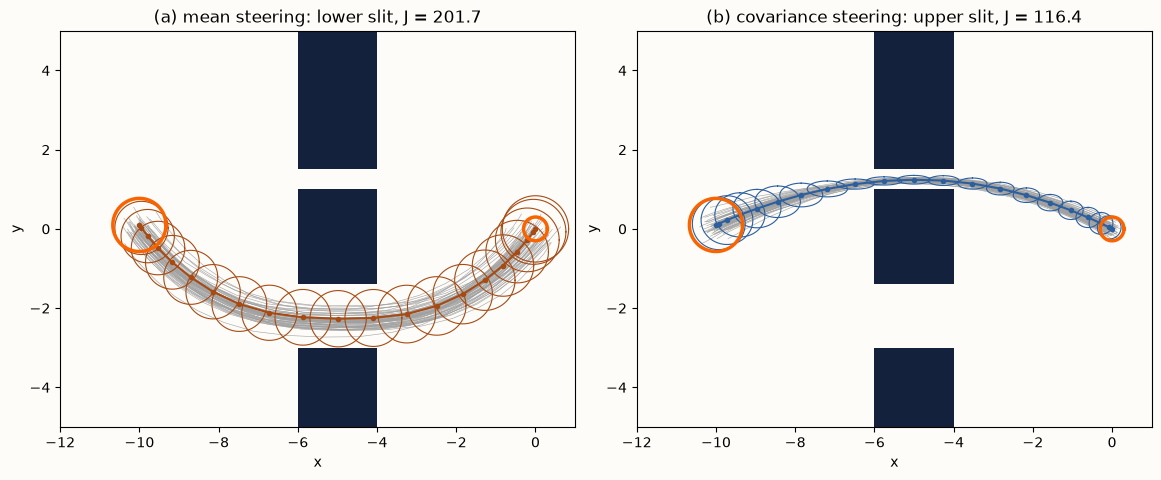

In [16]:
mean1 = plan(geom1, feedback=False)
cov1 = plan(geom1, feedback=True)          # about 2 min with MOSEK
fig_panels([(f"(a) mean steering: {mean1['slit']} slit, J = {mean1['J']:.1f}", mean1),
            (f"(b) covariance steering: {cov1['slit']} slit, J = {cov1['J']:.1f}", cov1)], geom1);

Mean steering detours (J ≈ 202). Covariance steering squeezes through the upper slit (J ≈ 116, 42% cheaper).

### Experiment 2: upper slit 0.2 wide (paper Fig. 4)

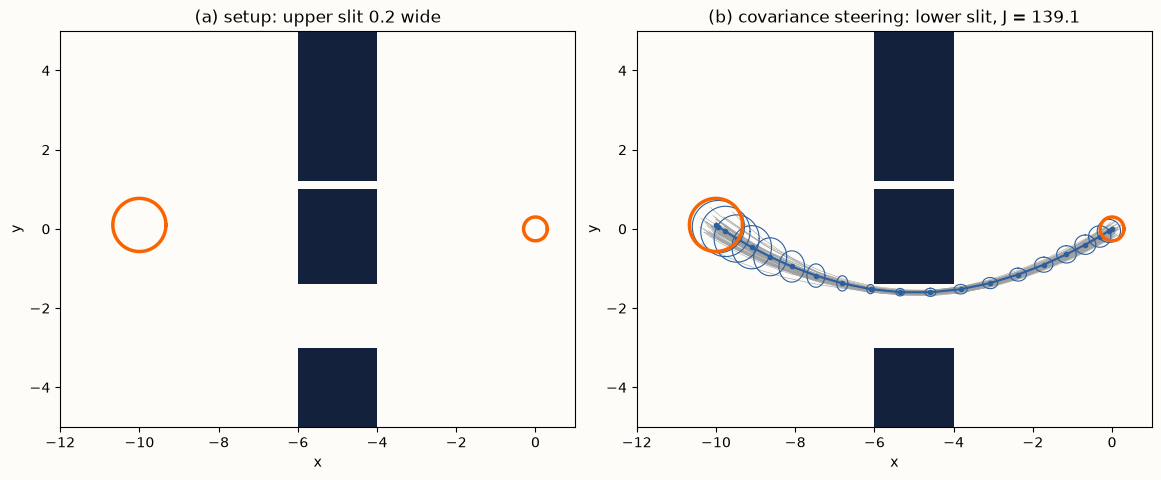

In [17]:
geom2 = double_slit(0.2)
cov2 = plan(geom2, feedback=True)          # about 1 min with MOSEK
fig_panels([("(a) setup: upper slit 0.2 wide", None),
            (f"(b) covariance steering: {cov2['slit']} slit, J = {cov2['J']:.1f}", cov2)], geom2);

Now the lower slit is cheaper (J ≈ 139). The sweep shows where the route switches (saved run; `fig_sweep(sweep())` redoes it in 12 min):

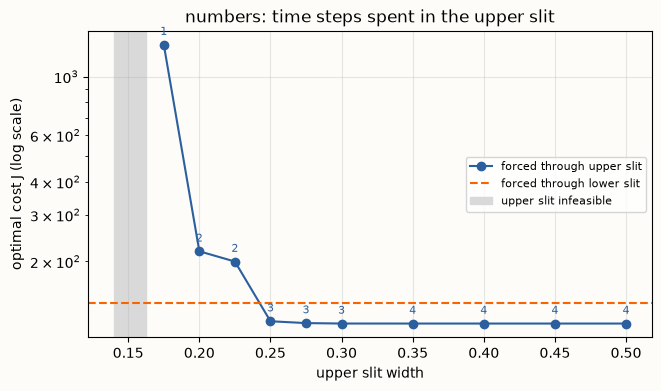

In [18]:
fig_sweep();

## Block 10. Monte Carlo verification

Simulate 200,000 vehicles with the real policy and compare with what the optimizer promised.

In [19]:
# ---- Block 10 (same code as covsteer.py) ----
def simulate(sol, n=20_000, seed=0):
    """Drive n noisy vehicles with the policy u_k = v_k + K_k y_k. Returns states and controls."""
    rng = np.random.default_rng(seed)
    x = mu_0 + rng.standard_normal((n, nx)) @ np.linalg.cholesky(Sigma_0).T
    y = x - mu_0
    xs, us = [x], []
    for k in range(N):
        u = sol["V"][k * nu:(k + 1) * nu] + y @ sol["K"][k].T      # Eq. 12
        w = rng.standard_normal((n, nx))
        x = x @ A.T + u @ B.T + w @ D.T                            # Eq. 1
        y = y @ A.T + w @ D.T                                      # Eq. 13
        xs.append(x)
        us.append(u)
    return np.array(xs), np.array(us)


def collides(p, geom):
    """True where position p (n x 2) is inside an obstacle or off the map."""
    x, y = p[:, 0], p[:, 1]
    x_min, x_max, y_min, y_max = WORKSPACE
    hit = (x < x_min) | (x > x_max) | (y < y_min) | (y > y_max)
    for a0, a1, b0, b1 in geom["obstacles"]:
        hit |= (x > a0) & (x < a1) & (y > b0) & (y < b1)
    return hit


def verify(sol, geom, n=200_000):
    """Simulate n runs and compare with what the optimizer promised."""
    xs, us = simulate(sol, n, seed=8)

    # how often each face of the chosen boxes is crossed (should be about eps)
    worst_face = 0.0
    for k in range(N):
        box = geom["regions"][sol["route"][:, k].argmax()]
        for i, sign, b in faces(box):
            for x in (xs[k], xs[k + 1]):
                worst_face = max(worst_face, np.mean(sign * x[:, i] > b))

    # collisions at the time steps, and along the true path between them
    # (acceleration is constant between steps, so the path is a parabola)
    hit_steps = np.any([collides(x[:, :2], geom) for x in xs], axis=0)
    hit_path = hit_steps.copy()
    for k in range(N):
        for t in np.linspace(0, dt, 11)[1:-1]:
            p = xs[k, :, :2] + xs[k, :, 2:] * t + 0.5 * us[k] * t**2
            hit_path |= collides(p, geom)

    cov_excess = np.linalg.eigvalsh(sol["Sigmas"][-1] - Sigma_N).max()
    return {"route": sol["slit"] + " slit",
            "J, optimizer": f"{sol['J']:.2f}",
            "J, simulated": f"{np.sum(us**2, axis=(0, 2)).mean():.2f}",
            "terminal covariance excess (<= 0 is met)": f"{cov_excess:+.0e}",
            f"worst face violation (allowed {eps})": f"{worst_face:.4f}",
            "collisions at time steps": f"{hit_steps.mean():.4f}",
            "collisions along the path": f"{hit_path.mean():.4f}"}


def table(columns):
    """Markdown table from {column name: verify() result}."""
    names = list(columns)
    lines = ["| | " + " | ".join(names) + " |",
             "|---" * (len(names) + 1) + "|"]
    for row in columns[names[0]]:
        lines.append(f"| {row} | " + " | ".join(columns[c][row] for c in names) + " |")
    return "\n".join(lines)

In [20]:
results = {"slit 0.5, mean": verify(mean1, geom1),
           "slit 0.5, covariance": verify(cov1, geom1),
           "slit 0.2, covariance": verify(cov2, geom2)}
Markdown(table(results))

| | slit 0.5, mean | slit 0.5, covariance | slit 0.2, covariance |
|---|---|---|---|
| route | lower slit | upper slit | lower slit |
| J, optimizer | 201.68 | 116.42 | 139.08 |
| J, simulated | 201.68 | 116.41 | 139.10 |
| terminal covariance excess (<= 0 is met) | +7e-02 | -9e-12 | -3e-11 |
| worst face violation (allowed 0.001) | 0.0011 | 0.0011 | 0.0011 |
| collisions at time steps | 0.0013 | 0.0000 | 0.0000 |
| collisions along the path | 0.0014 | 0.0000 | 0.0001 |

## Summary

| From | To | What changes |
|---|---|---|
| Open loop (block 5) | Closed loop (block 4, 6) | Feedback $K$ shapes the covariance; target met exactly |
| Free space (block 6) | Chance constraints (block 7) | Safety margin = 3.09 σ, so a smaller σ allows a closer path |
| One region | Many regions (block 8, 9) | Binaries choose the route; cutting planes certify optimality |

**Findings.** Covariance steering takes the narrow slit that mean steering cannot (116 vs 202), detours when the slit narrows to 0.2, and every probabilistic promise holds in simulation.

**Assumed:** $\mu_0, \Sigma_0, \Sigma_N$, $Q=0$, $R=I$. **Reconstructed:** geometry, read off the paper's figures.

### Try it: any upper-slit width (needs MOSEK, about 1 min)

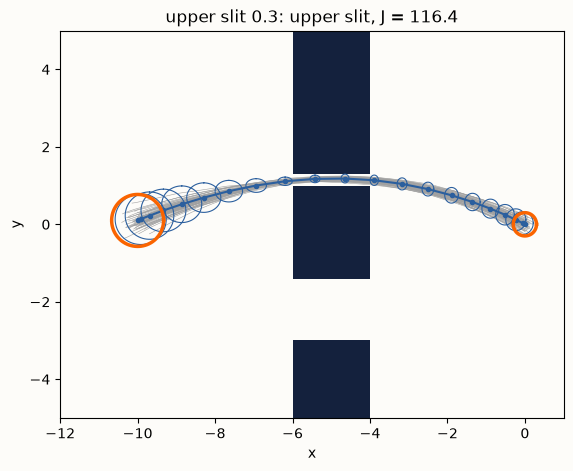

In [21]:
WIDTH = 0.3
geom = double_slit(WIDTH)
sol = algorithm1(geom, feedback=True)
fig_panels([(f"upper slit {WIDTH}: {sol['slit']} slit, J = {sol['J']:.1f}", sol)], geom, width=7);